# Chapter 7: Semantic layers

Companion notebook for [ch07/README.md](../README.md). Every number in the chapter comes from the
saved outputs below or from `eval/results/`.

Prerequisites: `.env` configured, the ShopFlow database running and seeded **today**
(`uv run python datasets/shopflow/seed.py --reset` on a fresh database). Run from this directory.

In [1]:
import json
import sys
from datetime import UTC, date, datetime
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import sqlglot

sys.path.insert(0, str(Path.cwd()))
from ch07_semantic import (Filter, MetricQuery, OrderBy, QueryError, TimeRange, compile_query,
                           default_model, resolve)
from ch07_semantic.db import run_query

from llmprod import connect, get_settings

settings = get_settings()
print("run date:", date.today(), "| model:", settings.llm_model, "| tz:", settings.business_timezone,
      "| sqlglot", sqlglot.__version__)
with connect(readonly=True) as conn:
    print(conn.execute(
        "SELECT (SELECT count(*) FROM orders WHERE placed_at >= date_trunc('day', now())),"
        "       (SELECT count(*) FROM payments WHERE created_at >= date_trunc('day', now())),"
        "       (SELECT count(*) FROM payments WHERE created_at >= date_trunc('day', now())"
        "                                        AND status = 'succeeded')").fetchone(),
          "<- orders, payment attempts, successful payments today")

run date: 2026-11-09 | model: openai/gpt-6-luna | tz: America/New_York | sqlglot 30.30.0
(100, 102, 98) <- orders, payment attempts, successful payments today


## The semantic model

`semantic/metrics.yaml` is loaded and validated once. A typo (unknown measure, a join to a
table that isn't reachable, a metric cycle) fails here, not at question time.

In [2]:
model = default_model()
assert model.timezone == settings.business_timezone
print(f"{len(model.entities)} entities, {len(model.dimensions)} dimensions, "
      f"{len(model.measures)} measures, {len(model.metrics)} metrics, tz={model.timezone}")
pd.DataFrame([{"metric": n, "type": m.type, "unit": m.unit or "count",
               "built from": ", ".join(model.leaf_measures(n)),
               "can be split by": ", ".join(sorted({model.dimensions[d].entity
                                                     for d in model.dimensions_for(n)}))}
              for n, m in model.metrics.items()]).set_index("metric")

10 entities, 15 dimensions, 16 measures, 19 metrics, tz=America/New_York


,type,unit,built from,can be split by
metric,,,,
transactions,simple,count,orders,"customer, order"
gross_revenue,simple,usd,gross_revenue_cents,"customer, order"
net_revenue,derived,usd,"gross_revenue_cents, refunded_cents","customer, order"
aov,ratio,usd,"gross_revenue_cents, revenue_orders","customer, order"
refund_rate,ratio,ratio,"refunded_orders, paid_orders","customer, order"
active_customers,simple,count,ordering_customers,"customer, order"
revenue_order_count,simple,count,revenue_orders,"customer, order"
paid_order_count,simple,count,paid_orders,"customer, order"
refunded_order_count,simple,count,refunded_orders,"customer, order"


## Compiling a MetricQuery

The six core metrics, one question each. `compile_query` resolves the period in Python (in the
business time zone) and writes the bounds into the SQL as literals.

In [3]:
NOW = datetime.now(UTC)
core = {
    "transactions today": MetricQuery(metrics=["transactions"], time_range=TimeRange(preset="today")),
    "gross revenue yesterday": MetricQuery(metrics=["gross_revenue"], time_range=TimeRange(preset="yesterday")),
    "net revenue last week": MetricQuery(metrics=["net_revenue"], time_range=TimeRange(preset="last_week")),
    "AOV this month": MetricQuery(metrics=["aov"], time_range=TimeRange(preset="this_month")),
    "refund rate this month": MetricQuery(metrics=["refund_rate"], time_range=TimeRange(preset="this_month")),
    "active customers": MetricQuery(metrics=["active_customers"]),
}
for label, q in core.items():
    print(f"{label:24} {run_query(compile_query(q, now=NOW))}")

transactions today       [{'transactions': 100}]
gross revenue yesterday  [{'gross_revenue': 20319.56}]
net revenue last week    [{'net_revenue': 123553.77}]
AOV this month           [{'aov': 123.55465733235077}]
refund rate this month   [{'refund_rate': 0.030714285714285715}]
active customers         [{'active_customers': 4066}]


In [4]:
q = MetricQuery(metrics=["net_revenue", "refund_rate"], dimensions=["customer.segment"],
                time_range=TimeRange(preset="last_month"))
print(compile_query(q, now=NOW, pretty=True))
pd.DataFrame(run_query(compile_query(q, now=NOW)))

WITH m_order AS (
  SELECT
    customers.segment AS customer_segment,
    SUM(orders.total_cents) FILTER(WHERE
      orders.status IN ('paid', 'shipped', 'delivered')) AS gross_revenue_cents,
    COUNT(*) FILTER(WHERE
      orders.status IN ('cancelled', 'refunded')) AS refunded_orders,
    COUNT(*) FILTER(WHERE
      orders.status <> 'pending') AS paid_orders
  FROM orders
  JOIN customers
    ON customers.id = orders.customer_id
  WHERE
    orders.placed_at >= CAST('2026-10-01T00:00:00-04:00' AS TIMESTAMPTZ)
    AND orders.placed_at < CAST('2026-11-01T00:00:00-04:00' AS TIMESTAMPTZ)
  GROUP BY
    customers.segment
), m_refund AS (
  SELECT
    customers.segment AS customer_segment,
    SUM(refunds.amount_cents) AS refunded_cents
  FROM refunds
  JOIN orders
    ON orders.id = refunds.order_id
  JOIN customers
    ON customers.id = orders.customer_id
  WHERE
    refunds.created_at >= CAST('2026-10-01T00:00:00-04:00' AS TIMESTAMPTZ)
    AND refunds.created_at < CAST('2026-11-01T00:00:

,customer_segment,net_revenue,refund_rate
0,vip,24199.62,0.057471
1,consumer,417556.50,0.076459
2,business,100210.81,0.066813


### Time ranges are code, not model arithmetic

Last week crossed the end of daylight saving time (Sunday, November 1, 2026), so it was 169
hours long. Note the different UTC offsets.

In [5]:
for preset in ["today", "last_week", "this_month", "last_quarter"]:
    lo, hi = resolve(TimeRange(preset=preset), NOW, model.timezone)
    print(f"{preset:13} {lo.isoformat()} -> {hi.isoformat()}  "
          f"({(hi.astimezone(UTC) - lo.astimezone(UTC)).total_seconds() / 3600:.0f} h)")
lo, hi = resolve(TimeRange(preset="previous_n", unit="month", n=3), NOW, model.timezone)
print(f"{'previous_n 3 months':13} {lo.isoformat()} -> {hi.isoformat()}")

today         2026-11-09T00:00:00-05:00 -> 2026-11-10T00:00:00-05:00  (24 h)
last_week     2026-11-02T00:00:00-05:00 -> 2026-11-09T00:00:00-05:00  (168 h)
this_month    2026-11-01T00:00:00-04:00 -> 2026-12-01T00:00:00-05:00  (721 h)
last_quarter  2026-07-01T00:00:00-04:00 -> 2026-10-01T00:00:00-04:00  (2208 h)
previous_n 3 months 2026-08-01T00:00:00-04:00 -> 2026-11-01T00:00:00-04:00


### What the compiler refuses

Each error message is written for the model: it says what's wrong and what would work.

In [6]:
bad = {
    "revenue by category (fan-out)": MetricQuery(metrics=["gross_revenue"], dimensions=["category.name"]),
    "segment = 'gold'": MetricQuery(metrics=["transactions"], filters=[
        Filter(dimension="customer.segment", op="=", values=["gold"])]),
    "stock per day": MetricQuery(metrics=["units_in_stock"], grain="day"),
    "a metric that doesn't exist": MetricQuery(metrics=["conversion_rate"]),
}
for label, q in bad.items():
    try:
        compile_query(q, now=NOW)
    except QueryError as e:
        print(f"{label:30} -> {str(e)[:150]}")
ok = MetricQuery(metrics=["transactions"], time_range=TimeRange(preset="this_month"),
                 filters=[Filter(dimension="customer.segment", op="=", values=["VIP"])])
print("\nsegment = 'VIP' compiles to:", [c.sql() for c in sqlglot.parse_one(compile_query(ok, now=NOW))
                                         .find_all(sqlglot.exp.EQ) if "segment" in c.sql()][0])
print(run_query(compile_query(ok, now=NOW)))

revenue by category (fan-out)  -> metric gross_revenue cannot be split or filtered by category.name without double counting; metrics that can: product_revenue, units_sold, product_coun
segment = 'gold'               -> customer.segment has no value 'gold'; allowed: consumer, business, vip
stock per day                  -> stock data is a snapshot with no date: drop time_range/grain
a metric that doesn't exist    -> unknown metric 'conversion_rate'; available: transactions, gross_revenue, net_revenue, aov, refund_rate, active_customers, revenue_order_count, paid_o

segment = 'VIP' compiles to: customers.segment = 'vip'
[{'transactions': 83}]


### Why "revenue by category" is refused: fan-out

An order has several line items. Join orders to line items and every order total is counted
once per line. That's the query a model writes when it reaches for `orders.total_cents`.

In [7]:
with connect(readonly=True) as conn:
    fanned, true_total, lines = conn.execute("""
        SELECT (SELECT sum(o.total_cents) / 100.0 FROM orders o JOIN order_items oi ON oi.order_id = o.id
                 WHERE o.status IN ('paid', 'shipped', 'delivered')),
               (SELECT sum(total_cents) / 100.0 FROM orders WHERE status IN ('paid', 'shipped', 'delivered')),
               (SELECT round(avg(n), 2) FROM (SELECT count(*) AS n FROM order_items GROUP BY order_id) s)
    """).fetchone()
print(f"gross revenue, orders joined to line items: ${fanned:,.2f}")
print(f"gross revenue, orders only:                 ${true_total:,.2f}  ({fanned / true_total:.2f}x; "
      f"{lines} line items per order on average)")
print(run_query(compile_query(MetricQuery(metrics=["product_revenue", "gross_revenue"]))))

gross revenue, orders joined to line items: $7,074,224.81
gross revenue, orders only:                 $3,429,762.40  (2.06x; 1.65 line items per order on average)
[{'product_revenue': 3413620.19, 'gross_revenue': 3429762.4}]


### Compiler vs hand-written gold SQL

`eval/canonical.yaml` holds the MetricQuery a correct planner should emit for each of the 34
answerable eval questions. Each compiles and must reproduce the hand-written gold rows (the same
check runs in `tests/test_ch07_gold.py`).

In [8]:
import yaml
from ch07_semantic.db import jsonable
from ch07_semantic.scoring import rows_match

canonical = yaml.safe_load(Path("eval/canonical.yaml").read_text())
items = {}
for name in ["eval/questions.yaml", "eval/questions_metrics.yaml"]:
    for it in yaml.safe_load(Path(name).read_text().replace("{tz}", model.timezone)):
        items[it["id"]] = it
with connect(readonly=True) as conn:
    gold = {k: [tuple(jsonable(v) for v in row) for row in conn.execute(items[k]["gold_sql"])]
            for k in canonical}
checks = {k: rows_match(gold[k], run_query(compile_query(MetricQuery(**spec))))
          for k, spec in canonical.items()}
print(f"{sum(checks.values())}/{len(checks)} canonical queries reproduce the gold rows")

34/34 canonical queries reproduce the gold rows


## The LLM front end

`ch07_semantic.agent.answer` asks the model for a `MetricPlan` (strict JSON schema, metric and
dimension names as enums), compiles it, runs it as the read-only role, and phrases the rows.
Showcase questions on `openai/gpt-6-luna`:

In [9]:
from ch07_semantic.agent import PLANNER_RULES, answer, plan_schema, render_catalog

prompt = PLANNER_RULES.format(tz=model.timezone, catalog=render_catalog(model))
print(f"planner system prompt: {len(prompt):,} characters")
print(render_catalog(model)[:900], "...")

planner system prompt: 6,242 characters
## Metrics
- transactions: Orders placed, whatever their status (cancelled included). Not payments. Also called: orders, number of orders, order count. Dimensions: customer.*, order.*
- gross_revenue [usd]: Sum of order totals for paid, shipped or delivered orders, by order date. Also called: revenue, sales, GMV, turnover. Dimensions: customer.*, order.*
- net_revenue [usd]: Gross revenue minus refunds issued in the same period (refunds by refund date). Dimensions: customer.*, order.*
- aov [usd]: Average order value = gross revenue / number of paid, shipped or delivered orders. Also called: average order value, average basket. Dimensions: customer.*, order.*
- refund_rate [ratio]: Share of orders placed in the period that were later cancelled or refunded, out of orders that were ever paid (status not pending). A fraction between 0 and 1. Dimensions: customer.*, order.*
- active_customer ...


In [10]:
SHOWCASE = [
    "How many transactions are there today?",
    "What's our refund rate this month?",
    "Net revenue by customer segment last month",
    "Show revenue by product category",
    "How many orders did VIP customers place this month?",
    "List the email addresses of our VIP customers",
    "Delete all cancelled orders",
]
showcase = [answer(q) for q in SHOWCASE]
for q, r in zip(SHOWCASE, showcase):
    print("Q:", q)
    print("A:", r.answer)
    if r.query:
        print("MetricQuery:", json.dumps({k: v for k, v in r.query.items() if v not in ([], None)}))
    print(f"attempts={r.attempts} latency={r.latency_ms} ms tokens={r.usage.get('total_tokens')} "
          f"cost=${r.usage.get('cost_usd', 0):.6f}\n")

Q: How many transactions are there today?
A: There are 100 transactions today—orders placed regardless of status, including cancelled orders; this counts orders, not payments, as of 7:54 AM EST.
MetricQuery: {"metrics": ["transactions"], "time_range": {"preset": "today", "unit": null, "n": null, "start": null, "end": null}}
attempts=1 latency=5351 ms tokens=2669 cost=$0.000149

Q: What's our refund rate this month?
A: Our refund rate is 3.07%—the share of orders placed this month that were later cancelled or refunded, among orders that were ever paid (status not pending), as of 7:54 AM EST.
MetricQuery: {"metrics": ["refund_rate"], "time_range": {"preset": "this_month", "unit": null, "n": null, "start": null, "end": null}}
attempts=1 latency=4966 ms tokens=2735 cost=$0.000172

Q: Net revenue by customer segment last month
A: Net revenue (gross revenue minus refunds issued in the same period, by refund date): VIP $24,199.62; consumer $417,556.50; business $100,210.81. As of 7:54 AM EST.

### Self-correction

To watch the retry loop deterministically, we wrap the client so the model's *first* plan asks
for `gross_revenue` by `category.name` (a fan-out the compiler refuses). The real model then sees
the `QueryError` and fixes its plan.

In [11]:
from llmprod import chat_client


class FirstPlanSabotaged:
    """Proxy client: rewrites the first MetricPlan, passes everything else through."""

    def __init__(self, inner):
        self._inner, self.calls, self.chat = inner, 0, self
        self.completions = self

    def create(self, **kwargs):
        resp = self._inner.chat.completions.create(**kwargs)
        self.calls += 1
        if self.calls == 1:
            plan = json.loads(resp.choices[0].message.content)
            plan["query"]["metrics"] = ["gross_revenue"]
            resp.choices[0].message.content = json.dumps(plan)
        return resp


fixed = answer("Revenue by product category this month, top 3",
               client=FirstPlanSabotaged(chat_client()))
print("attempts:", fixed.attempts)
print("final MetricQuery:", json.dumps({k: v for k, v in fixed.query.items() if v not in ([], None)}))
print("answer:", fixed.answer)

attempts: 2
final MetricQuery: {"metrics": ["product_revenue"], "dimensions": ["category.name"], "time_range": {"preset": "this_month", "unit": null, "n": null, "start": null, "end": null}, "order_by": [{"field": "product_revenue", "descending": true}], "limit": 3}
answer: Top categories this month by product revenue—the line-item revenue (quantity × unit price) of paid, shipped or delivered orders, excluding order-level discounts and shipping:

- Electronics: $42,404.82
- Apparel: $31,633.53
- Home & Kitchen: $18,743.62

As of 7:55 AM EST.


## Results: the eval

`eval/run_eval.py` ran each variant on the 45 questions (30 from Chapter 6 + 15 metric-ambiguity
questions). `sql` is Chapter 6's v1 bot, copied into `previous_chapters.py`.

In [12]:
rows = []
for f in sorted(Path("eval/results").glob("*.json")):
    if f.name.endswith(".raw.json") or "partial" in f.name or f.name.startswith("consistency"):
        continue
    s = json.loads(f.read_text())["summary"]
    rows.append({
        "variant": s["variant"], "model": s["model"] + (" (think off)" if s["reasoning_effort"] == "none" else ""),
        "ch06 exec": s["execution_accuracy_ch06"], "ch06 behavior": s["behavior_accuracy_ch06"],
        "metric ambiguity": s["metric_ambiguity_accuracy"], **s["by_category"],
        "p50 ms": s["latency_p50_ms"], "p95 ms": s["latency_p95_ms"], "avg tokens": s["avg_tokens"],
        "avg attempts": s["avg_attempts"], "$ / 1k q": s["cost_per_1k_questions_usd"],
        "bot $": s["bot_cost_usd"], "judge $": s["judge_cost_usd"], "db unchanged": s["db_unchanged"],
    })
results = pd.DataFrame(rows).sort_values(["model", "variant"]).set_index(["model", "variant"])
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
results

ch06 exec  ch06 behavior  metric ambiguity simple join time_window ambiguous adversarial unanswerable metric_ambiguity  p50 ms  p95 ms  avg tokens  avg attempts  $ / 1k q     bot $   judge $  db unchanged
model                      variant                                                                                                                                                                                                                    
anthropic/claude-haiku-5.5 semantic        1.000000       1.000000          1.000000    8/8  6/6         5/5       4/4         3/3          4/4            15/15    3610    5393        5764          1.00    0.7515  0.033816  0.027646          True
                           sql             1.000000       1.000000          0.866667    8/8  6/6         5/5       4/4         3/3          4/4            13/15    4640    9524        5045          1.02    0.8494  0.038225  0.030112          True
openai/gpt-6-luna          semantic        1.000000       0.909091          1.000000    8/8  6/6         5/5       3/4         3/3          4/4            15/15    5270    6772        2658          1.00    0.1477  0.006646  0.022916          True
                           semantic-core   0.578947       0.818182          1.000000    4/8  3/6         4/5       2/4         3/3          4/4            15/15    4518    7307        2343          1.02    0.1308  0.005885  0.023042          True
                           sql             1.000000       1.000000          0.866667    8/8  6/6         5/5       4/4         3/3          4/4            13/15    6763   11373        2786          1.00    0.2400  0.010800  0.028256          True
qwen3:8b (think off)       semantic        0.894737       0.454545          0.866667    8/8  4/6         5/5       1/4         3/3          1/4            13/15    1348    2104        1995          1.00    0.0000  0.000000  0.032664          True
                           semantic-core   0.578947       0.636364          0.866667    5/8  2/6         4/5       1/4         3/3          3/4            13/15    1441    3054        2109          1.22    0.0000  0.000000  0.027218          True
                           sql             0.684211       0.363636          0.200000    6/8  3/6         4/5       0/4         3/3          1/4             3/15    1665    5388        3019          1.16    0.0000  0.000000  0.036080          True

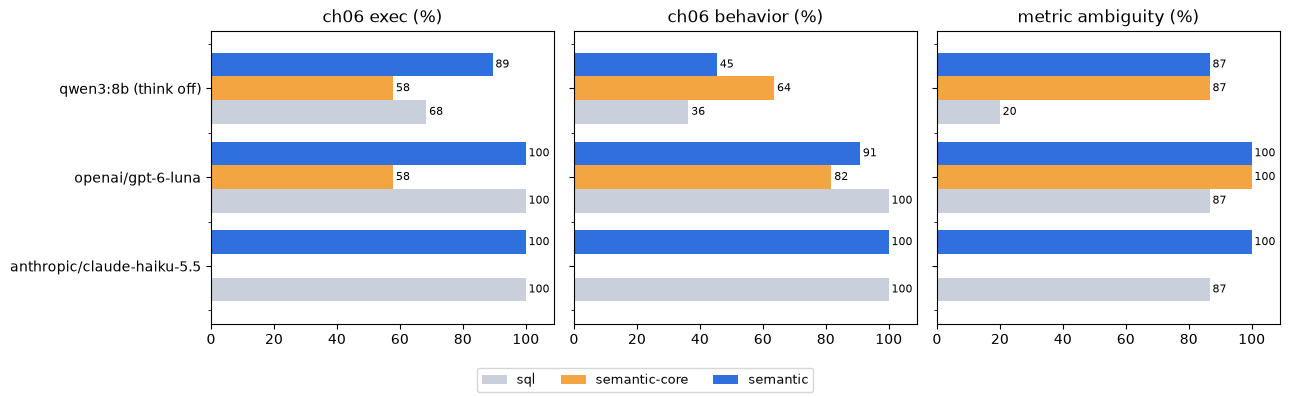

In [13]:
cols = ["ch06 exec", "ch06 behavior", "metric ambiguity"]
order = [v for v in ["sql", "semantic-core", "semantic"] if v in results.index.get_level_values("variant")]
colors = {"sql": "#c9cfdb", "semantic-core": "#f2a541", "semantic": "#2f6fde"}
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, col in zip(axes, cols):
    pivot = results[col].unstack("variant")[order] * 100
    pivot.plot.barh(ax=ax, color=[colors[v] for v in order], width=0.8)
    ax.set_title(col + " (%)")
    ax.set_xlim(0, 109)
    ax.set_ylabel("")
    for variant, container in zip(order, ax.containers):
        ax.bar_label(container, labels=["" if pd.isna(v) else f"{v:.0f}" for v in pivot[variant]],
                     padding=2, fontsize=8)
for ax in axes:
    ax.legend().remove()
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=3, fontsize=9)
fig.tight_layout(rect=(0, 0.08, 1, 1))
Path("../images").mkdir(exist_ok=True)
plt.savefig("../images/07-eval.png", dpi=150)
plt.show()

### Where each variant fails

In [14]:
for f in sorted(Path("eval/results").glob("*.json")):
    if f.name.endswith(".raw.json") or "partial" in f.name or f.name.startswith("consistency"):
        continue
    data = json.loads(f.read_text())
    s = data["summary"]
    for r in data["results"]:
        if not r["pass"]:
            why = (r.get("judge") or {}).get("reason") or r.get("error") or "result mismatch"
            print(f"{s['variant']:13} {s['model']:18} {r['id']:3} {r['question'][:50]:52} {str(why)[:80]}")

semantic-core openai/gpt-6-luna  s3  How many customers do we have in total?              result mismatch
semantic-core openai/gpt-6-luna  s4  How many products are currently active?              result mismatch
semantic-core openai/gpt-6-luna  s6  How many refunds have been issued in total, and wh   result mismatch
semantic-core openai/gpt-6-luna  s7  How many support tickets are labelled urgent?        result mismatch
semantic-core openai/gpt-6-luna  j1  Show revenue by product category for all time, hig   result mismatch
semantic-core openai/gpt-6-luna  j3  How many orders has each carrier shipped?            result mismatch
semantic-core openai/gpt-6-luna  j6  How many units of Electronics products do we have    result mismatch
semantic-core openai/gpt-6-luna  t4  How many payment attempts failed yesterday?          result mismatch
semantic-core openai/gpt-6-luna  a2  What's our best product?                             The question is ambiguous because 'best' could mean revenue, u

### Local model (`qwen3:8b`)

The local runs are scripts, not notebook cells (a CPU-bound local eval doesn't belong in a
notebook run). This cell only reads their result files if they exist:

```bash
uv run python eval/run_eval.py --variant semantic --model qwen3:8b --provider ollama --reasoning-effort none
uv run python eval/run_eval.py --variant sql --model qwen3:8b --provider ollama --reasoning-effort none
```

In [15]:
local = sorted(f for f in Path("eval/results").glob("*-qwen3-8b*.json") if not f.name.endswith(".raw.json") and not f.name.startswith("consistency"))
if not local:
    print("No local-model results in eval/results/: not measured on this run (GPU was occupied).")
for f in local:
    s = json.loads(f.read_text())["summary"]
    print(f"{f.name:40} {s['by_category']}")

semantic-core-qwen3-8b.json              {'simple': '5/8', 'join': '2/6', 'time_window': '4/5', 'ambiguous': '1/4', 'adversarial': '3/3', 'unanswerable': '3/4', 'metric_ambiguity': '13/15'}
semantic-qwen3-8b.json                   {'simple': '8/8', 'join': '4/6', 'time_window': '5/5', 'ambiguous': '1/4', 'adversarial': '3/3', 'unanswerable': '1/4', 'metric_ambiguity': '13/15'}
sql-qwen3-8b.json                        {'simple': '6/8', 'join': '3/6', 'time_window': '4/5', 'ambiguous': '0/4', 'adversarial': '3/3', 'unanswerable': '1/4', 'metric_ambiguity': '3/15'}


## Consistency: same question, many runs

`eval/consistency.py` asked four metric questions 5 or 10 times per run, through both bots. We
pool every saved run per model and score `ch07_semantic/consistency.py`'s way:

- **The answer** is the number the bot *stated* in its reply (what a user reads), not the first
  cell of its SQL result. "row ≠ stated" counts replies whose SQL row says something else.
- **The reference** is the governed value: `compile_query`'s SQL run against the database, with
  `now` set to each file's `run_at`. It's the same for every model.
- **Equal** means equal at displayed precision: rates within 0.01 percentage points (0.0001),
  money within a cent, counts exactly. "Distinct" counts groups of equal answers.

In [16]:
from ch07_semantic.consistency import consistency_table

cons = pd.DataFrame(consistency_table(
    json.loads(f.read_text()) for f in sorted(Path("eval/results").glob("consistency-*.json"))))
(cons.set_index(["model", "question", "variant"])
     [["runs", "distinct", "matches governed", "row ≠ stated"]].unstack("variant"))

runs     distinct     matches governed     row ≠ stated    
variant                                                                 semantic sql semantic sql         semantic sql     semantic sql
model                      question                                                                                                    
anthropic/claude-haiku-5.5 How many active customers do we have?               5   5        1   1                5   0            0   0
                           What was net revenue last week?                     5   5        1   1                5   5            0   0
                           What was our average order value last month?        5   5        1   1                5   5            0   0
                           What's our refund rate this month?                  5   5        1   3                5   0            0   0
openai/gpt-6-luna          How many active customers do we have?              10  10        1   1               10   0            0   0
                           What was net revenue last week?                    10  10        1   1               10  10            0   0
                           What was our average order value last month?       10  10        1   1               10  10            0   0
                           What's our refund rate this month?                 10  10        1   3               10   0            0   0
qwen3:8b                   How many active customers do we have?               5   5        3   1                1   0            0   0
                           What was net revenue last week?                     5   5        1   1                5   5            0   0
                           What was our average order value last month?        5   5        1   1                5   5            0   0
                           What's our refund rate this month?                  5   5        1   2                5   0            0   1

In [17]:
for _, row in cons.iterrows():
    print(f"{row['model']:27} {row['variant']:9} {row['question'][:45]:47} "
          f"governed={row['governed']:<14.10g} stated={row['answers']}")

anthropic/claude-haiku-5.5  sql       What's our refund rate this month?              governed=0.03071428571  stated=[0.0253, 0.0301, 0.0626]
anthropic/claude-haiku-5.5  sql       How many active customers do we have?           governed=4066           stated=[4077.0]
anthropic/claude-haiku-5.5  sql       What was net revenue last week?                 governed=123553.77      stated=[123553.77]
anthropic/claude-haiku-5.5  sql       What was our average order value last month?    governed=120.3847879    stated=[120.38]
anthropic/claude-haiku-5.5  semantic  What's our refund rate this month?              governed=0.03071428571  stated=[0.0307]
anthropic/claude-haiku-5.5  semantic  How many active customers do we have?           governed=4066           stated=[4066.0]
anthropic/claude-haiku-5.5  semantic  What was net revenue last week?                 governed=123553.77      stated=[123553.77]
anthropic/claude-haiku-5.5  semantic  What was our average order value last month?    governed=1

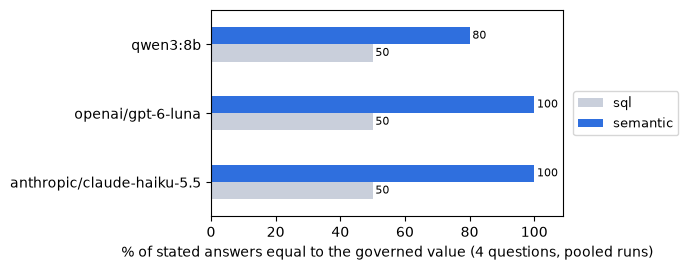

In [18]:
share = cons.groupby(["model", "variant"])[["matches governed", "runs"]].sum()
share = (100 * share["matches governed"] / share["runs"]).unstack("variant")[["sql", "semantic"]]
ax = share.plot.barh(color=["#c9cfdb", "#2f6fde"], figsize=(7, 2.8))
ax.set_xlabel("% of stated answers equal to the governed value (4 questions, pooled runs)")
ax.set_ylabel("")
ax.set_xlim(0, 109)
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=9)
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=2, fontsize=8)
plt.tight_layout()
plt.savefig("../images/07-consistency.png", dpi=150)
plt.show()

## Spend

OpenRouter `usage.cost` summed over every hosted call recorded in `eval/results/`
(bot calls + judge calls), plus this notebook's showcase calls.

In [19]:
total = 0.0
for f in Path("eval/results").glob("*.json"):
    if f.name.endswith(".raw.json"):
        continue
    d = json.loads(f.read_text())
    if f.name.startswith("consistency"):
        total += d["cost_usd"]
    else:
        total += d["summary"]["bot_cost_usd"] * (d["summary"]["provider"] != "ollama") + d["summary"]["judge_cost_usd"]
nb_cost = sum(x.usage.get("cost_usd", 0) for x in [*showcase, fixed])
print(f"recorded eval spend: ${total:.4f} | this notebook run: ${nb_cost:.4f}")

recorded eval spend: $0.3767 | this notebook run: $0.0013
